In [387]:
import os
from pathlib import Path
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# === Reference Sources ===
# https://dps.psx.com.pk/
# https://www.psx.com.pk/
# https://sarmaaya.pk/mutual-funds/
# https://sarmaaya.pk/forex/currency/USD

#| Use Case                        | Interval | Timeframe  |
#| ------------------------------- | -------- | ---------- |
#| Short-term trading              | Daily    | Week/Month |
#| Mid-term trend following        | Weekly   | Quarter    |
#| Long-term trend/investment view | Monthly  | Year/All   |
#| Portfolio backtesting           | Monthly  | All        |
#| Gold & Index trend tracking     | Weekly   | Year       |
#| MIF/MGF NAV trends              | Daily    | Quarter    |

#| Use Case                  | Interval  | Timeframe       |
#| ------------------------- | --------- | --------------- |
#| Short-term swing trades   | Daily     | Month, Quarter  |
#| Medium-term trend         | Weekly    | Half-Year, Year |
#| Long-term investment view | Monthly   | Year, All       |
#| Portfolio-level smoothing | Quarterly | All             |

#Use Case	Suggested Settings
#Gold or KSE Trend Tracking	interval='Weekly', timeframe='Year'
#NAV Trend for MIF / MIIF	interval='Daily', timeframe='Quarter' or 'Month'
#Backtest long-term fund trends	interval='Monthly', timeframe='All'
#Portfolio movement in short term	interval='Daily', timeframe='Week' or 'Month'

# === Use Case Matrix ===
# Short-term swing trades   → Daily, Month/Quarter
# Medium-term trend         → Weekly, Half-Year/Year
# Long-term investment view → Monthly, Year/All
# Portfolio backtesting     → Quarterly, All
# Gold or Index tracking    → Weekly, Year
# MIF/MGF NAV trend         → Daily, Quarter or Month

In [398]:
# === FUNCTIONS ===
def load_price_data(instrument):
    instrument = instrument.upper()
    
    if instrument not in INSTRUMENT_PATHS:
        raise ValueError(f"Unknown instrument: {instrument}. Available: {list(INSTRUMENT_PATHS.keys())}")
    
    file_path = INSTRUMENT_PATHS[instrument]
    print(f"Loading data for {instrument} from {file_path}")
    
    df = pd.read_excel(file_path)
    return df

def clean_price_data(df):
    """
    Cleans raw price data with 'datetime' and 'price' columns.
    
    Returns:
        pd.DataFrame: Cleaned DataFrame with datetime index and float price.
    """

    # Step 1: Rename columns if needed
    df = df.rename(columns=lambda x: x.strip().lower())
    if 'datetime' not in df.columns or 'price' not in df.columns:
        raise ValueError("DataFrame must have 'datetime' and 'price' columns")

    # Step 2: Parse datetime and convert price to float
    df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

    # Step 3: Drop rows with invalid datetime or price
    df = df.dropna(subset=['datetime', 'price'])

    # Step 4: Remove duplicates
    df = df.drop_duplicates(subset=['datetime'], keep='last')

    # Step 5: Set index and sort
    df = df.set_index('datetime')
    df = df[~df.index.duplicated(keep='last')]
    df = df.sort_index()

    # Step 6: Filter out future dates or unreasonable dates
    today = pd.Timestamp.today()
    df = df[df.index <= today]
    df = df[df.index >= pd.Timestamp("1990-01-01")]  # Adjust if needed

    # Step 7: Remove non-positive prices
    df = df[df['price'] > 0]

    # Step 8 (Optional): Fill missing business days with NaNs
    # all_days = pd.date_range(start=df.index.min(), end=df.index.max(), freq='B')
    # df = df.reindex(all_days)

    return df

def resample_price_data(df, interval='Weekly'):
    """
    Resample daily close price data to a given interval using the last available close price.

    Parameters:
        df (pd.DataFrame): DataFrame with 'datetime' index and 'price' column.
        interval (str): Interval to resample. Options: 'Daily', 'Weekly', 'Monthly', 'Quarterly', 'Yearly'.

    Returns:
        pd.DataFrame: Resampled DataFrame.
    """
    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("DataFrame must have a DatetimeIndex.")

    rule_map = {
        'Daily': 'D',
        'Weekly': 'W',
        'Monthly': 'M',
        'Quarterly': 'Q',
        'Yearly': 'Y'
    }

    if interval not in rule_map:
        raise ValueError(f"Unsupported interval: {interval}")

    return df.resample(rule_map[interval]).last().dropna()


def filter_by_timeframe(df, timeframe='All'):
    """
    Filters a DataFrame by a financial timeframe.

    Parameters:
        df (pd.DataFrame): Must have a DatetimeIndex.
        timeframe (str): One of 'Day', 'Week', 'Month', 'Quarter', 'Half-Year', 'Year', 'YTD', 'All'

    Returns:
        pd.DataFrame: Filtered DataFrame
    """

    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("DataFrame must have a DatetimeIndex.")

    if timeframe == 'All':
        return df

    last_date = df.index.max()

    if timeframe == 'Day':
        start_date = last_date - pd.DateOffset(days=1)
    elif timeframe == 'Week':
        start_date = last_date - pd.DateOffset(weeks=1)
    elif timeframe == 'Month':
        start_date = last_date - pd.DateOffset(months=1)
    elif timeframe == 'Quarter':
        start_date = last_date - pd.DateOffset(months=3)
    elif timeframe == 'Half-Year':
        start_date = last_date - pd.DateOffset(months=6)
    elif timeframe == 'Year':
        start_date = last_date - pd.DateOffset(years=1)
    elif timeframe == 'YTD':
        start_date = pd.Timestamp(last_date.year, 1, 1)
    else:
        raise ValueError(f"Unsupported timeframe: {timeframe}")

    filtered_df = df.loc[start_date:]
    print(f"Showing data from {start_date.date()} to {last_date.date()}")
    return filtered_df

def compute_indicators(df: pd.DataFrame, price_col: str) -> pd.DataFrame:
    """Add Bollinger Bands and Moving Averages to the DataFrame."""
    df['SMA_20'] = df[price_col].rolling(20).mean()
    std_20 = df[price_col].rolling(20).std()
    df['Upper_Band'] = df['SMA_20'] + 2 * std_20
    df['Lower_Band'] = df['SMA_20'] - 2 * std_20
    return df

def compute_moving_averages(df: pd.DataFrame, interval: str, price_col: str) -> pd.DataFrame:
    """Add interval-specific moving averages."""
    ma_map = {
        'Weekly': {'MA_4W': 4},
        'Monthly': {'MA_6M': 6, 'MA_12M': 12}
    }

    for label, window in ma_map.get(interval, {}).items():
        df[label] = df[price_col].rolling(window).mean()

    return df

def plot_price(df: pd.DataFrame, instrument: str, interval: str, timeframe: str, price_col: str) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(16, 8), facecolor='white')  # Set figure background to white
    ax.set_facecolor('white')  # Set plot area background to white

    # Plot main price and indicators
    ax.plot(df.index, df[price_col], label='Price', color='black', linewidth=1.5)
    ax.plot(df.index, df['SMA_20'], label='20-SMA', color='blue')
    ax.plot(df.index, df['Upper_Band'], label='Upper Band', linestyle='--', color='green')
    ax.plot(df.index, df['Lower_Band'], label='Lower Band', linestyle='--', color='red')

    # Plot any extra moving averages
    for col in df.columns:
        if 'MA_' in col:
            ax.plot(df.index, df[col], label=col, linestyle='--')

    # Set title and labels with black text
    ax.set_title(f'{instrument} | {interval} Prices with Bollinger Bands & MAs', color='black')
    ax.set_xlabel('Date', color='black')
    ax.set_ylabel('Price', color='black')

    # Format ticks and grid
    ax.tick_params(axis='both', colors='black')
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    fig.autofmt_xdate()

    # Format legend
    legend = ax.legend(loc='upper left')
    for text in legend.get_texts():
        text.set_color('black')

    # Optional: Make axis spines black
    for spine in ax.spines.values():
        spine.set_edgecolor('black')

    # Optional: Make grid lighter gray
    ax.grid(True, color='lightgray')

    fig.tight_layout()
    return fig

def save_plot(instrument, interval, timeframe, fig=None, includeTime=False):
    # Convert inputs to uppercase
    instrument = instrument.upper()
    interval = interval.upper()
    timeframe = timeframe.upper()

    # Today's date (for folder and filename)
    today = datetime.now()
    today_str = today.strftime("%Y-%m-%d")
    date_str = today.strftime("%Y-%m-%d") if not includeTime else today.strftime("%Y%m%d-%H%M%S")

    # Build directory path and ensure it exists
    export_dir = Path(f"D:/repos/PriceData/Exports/{today_str}")
    export_dir.mkdir(parents=True, exist_ok=True)

    # Construct filename
    filename = f"{instrument}-{interval}-{timeframe}-{date_str}.png"
    full_path = export_dir / filename

    # Save plot (overwrite if exists)
    if fig is None:
        plt.savefig(full_path, bbox_inches='tight', dpi=300)
    else:
        fig.savefig(full_path, bbox_inches='tight', dpi=300)

    print(f"✅ Plot saved to: {full_path}")

In [399]:
# === CONFIGURATION ===
INSTRUMENT_PATHS = {
    # Meezan Funds
    "MIF": "D:/repos/PriceData/MIF.xlsx",
    "MGF": "D:/repos/PriceData/MGF.xlsx",
    
    # Indices
    "KSE100": "D:/repos/PriceData/KSE100.xlsx",
    "KMI30": "D:/repos/PriceData/KMI30.xlsx",
    
    # Gold
    "GOLDPK": "D:/repos/PriceData/GoldPK.xlsx",
    "GOLDINT": "D:/repos/PriceData/GoldINT.xlsx",
}

sheet_name = 0
date_column = 'datetime'
price_column = 'price'

# === User Input ===
#instrument = input("Enter Instrument (MIF, MGF, KSE100, KMI30, GoldPK, GoldINT): ")
#interval = input("Enter interval (Daily, Weekly, Monthly, etc): ")
#timeframe = input("Enter timeframe (Day, Week, Month, etc): ")

In [400]:
# === CUSTOM FILTER TIME FRAME ===
#start_date = '2022-01-01'  # Optional: Set your desired time frame
#end_date = '2025-01-01'
#df = df.loc[start_date:end_date]

In [401]:
def process_instrument(instrument, interval, timeframe, price_column="price"):
    try:
        # === LOAD DATA, CLEAN, CUSTOM FILTER TIME FRAME, SELECT INTERVAL & TIMEFRAME ===
        df = load_price_data(instrument)
        df = clean_price_data(df)
        df = resample_price_data(df, interval=interval) # 'Daily', 'Weekly', 'Monthly', 'Quarterly', 'Yearly'
        df = filter_by_timeframe(df, timeframe=timeframe) #'Day', 'Week', 'Month', 'Quarter', 'Half-Year', 'Year', 'YTD', 'All'
        df = compute_indicators(df, price_column)
        df = compute_moving_averages(df, interval, price_column)
        fig = plot_price(df, instrument, interval, timeframe, price_column)
        save_plot(instrument=instrument, interval=interval, timeframe=timeframe)
        plt.show()
    except Exception as e:
        print(f"❌ Error processing {instrument}: {e}")


📊 Processing: MIF
Loading data for MIF from D:/repos/PriceData/MIF.xlsx
Showing data from 2025-05-06 to 2025-08-06
✅ Plot saved to: D:\repos\PriceData\Exports\2025-08-07\MIF-DAILY-QUARTER-2025-08-07.png


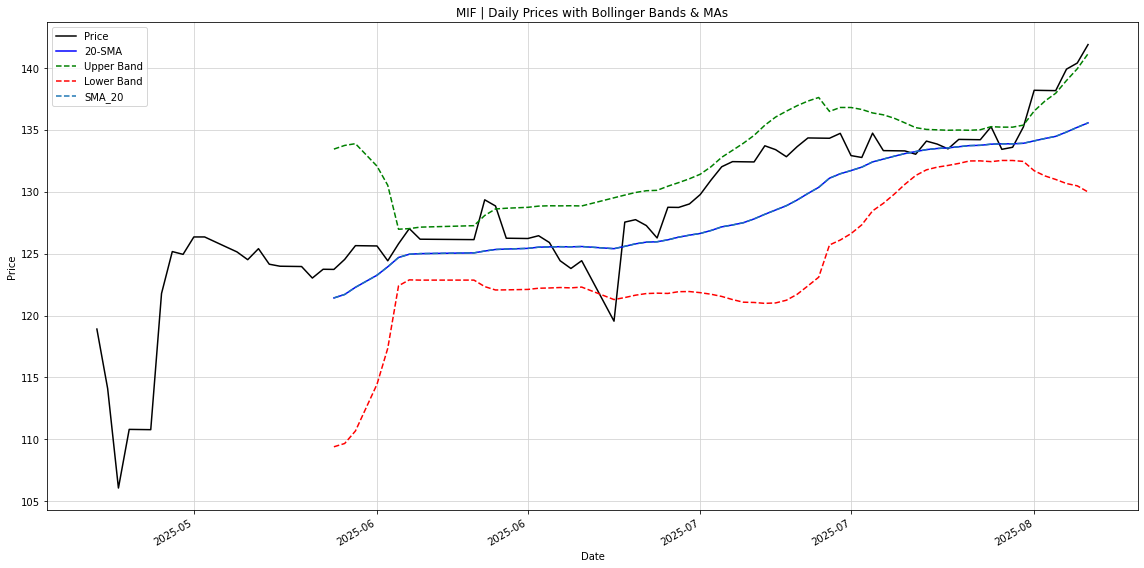


📊 Processing: MGF
Loading data for MGF from D:/repos/PriceData/MGF.xlsx
Showing data from 2025-05-04 to 2025-08-04
✅ Plot saved to: D:\repos\PriceData\Exports\2025-08-07\MGF-DAILY-QUARTER-2025-08-07.png


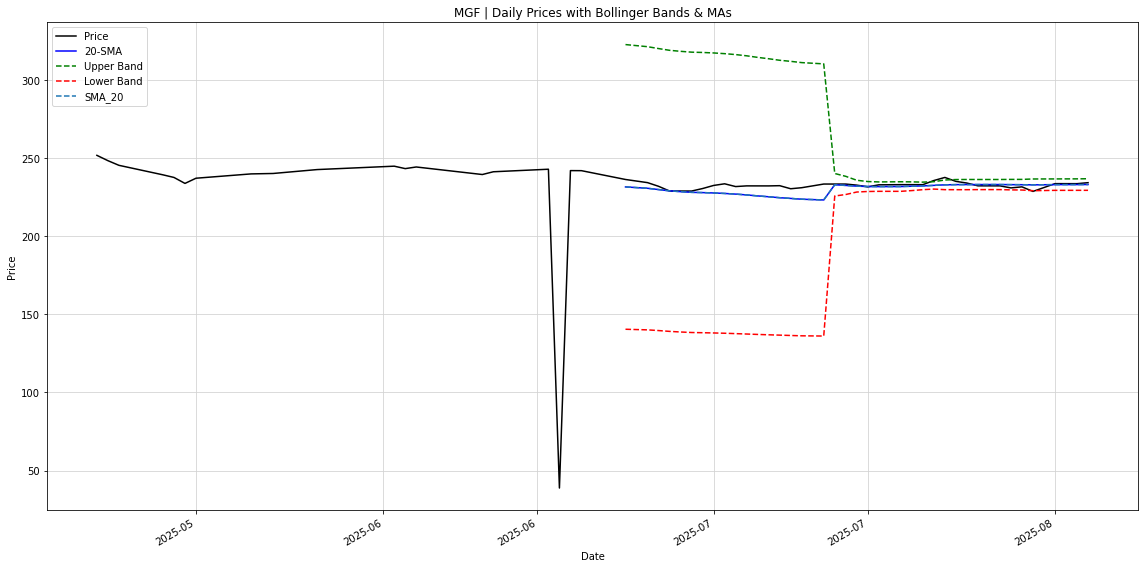


📊 Processing: KSE100
Loading data for KSE100 from D:/repos/PriceData/KSE100.xlsx
Showing data from 2025-05-06 to 2025-08-06
✅ Plot saved to: D:\repos\PriceData\Exports\2025-08-07\KSE100-DAILY-QUARTER-2025-08-07.png


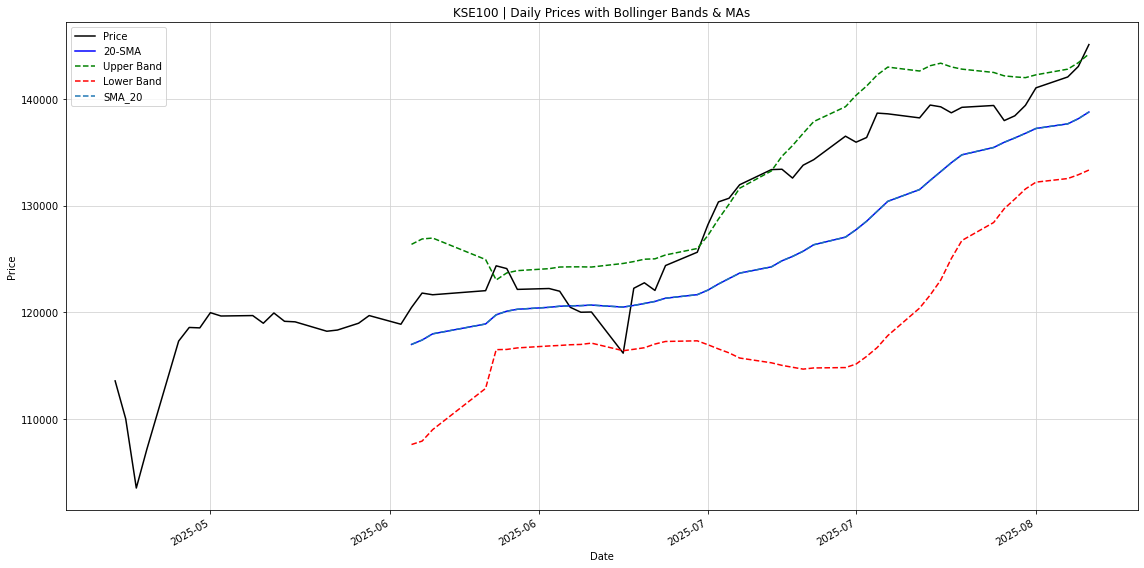


📊 Processing: KMI30
Loading data for KMI30 from D:/repos/PriceData/KMI30.xlsx
Showing data from 2025-05-06 to 2025-08-06
✅ Plot saved to: D:\repos\PriceData\Exports\2025-08-07\KMI30-DAILY-QUARTER-2025-08-07.png


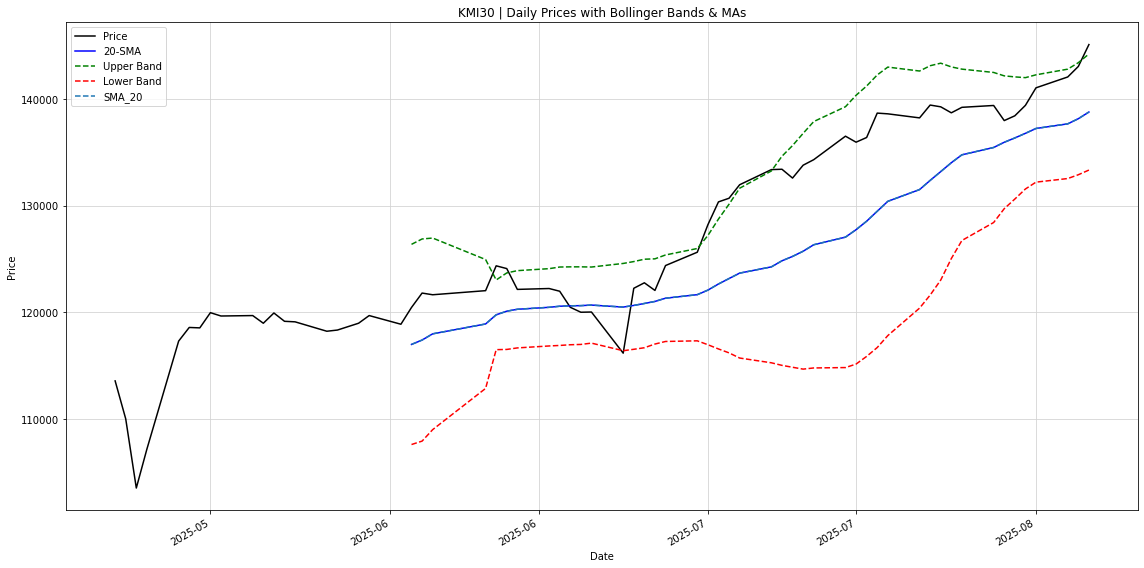


📊 Processing: GOLDPK
Loading data for GOLDPK from D:/repos/PriceData/GoldPK.xlsx
Showing data from 2025-05-06 to 2025-08-06
✅ Plot saved to: D:\repos\PriceData\Exports\2025-08-07\GOLDPK-DAILY-QUARTER-2025-08-07.png


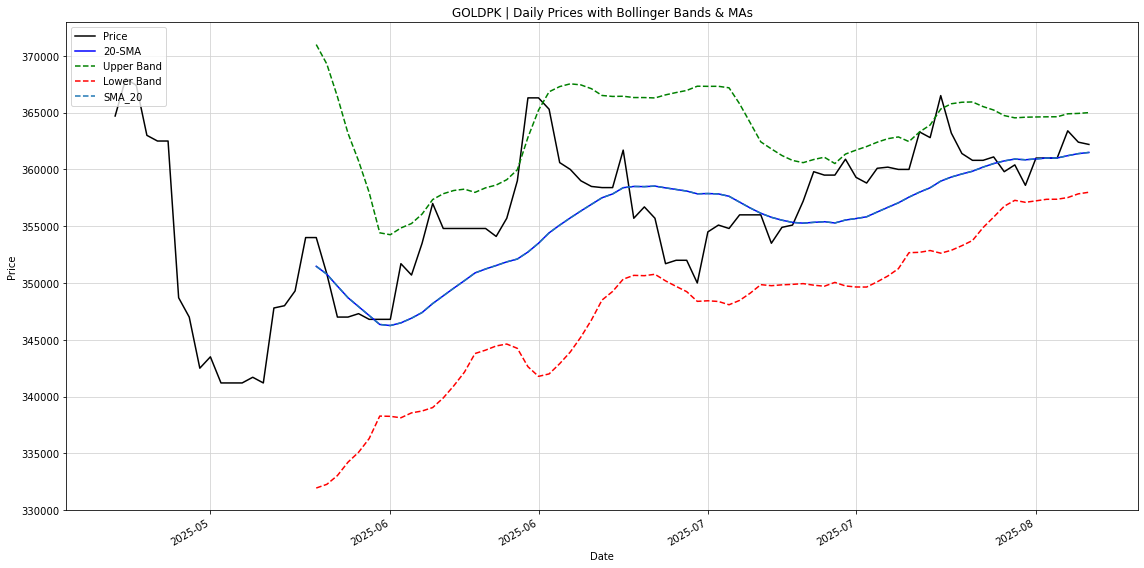


📊 Processing: GOLDINT
Loading data for GOLDINT from D:/repos/PriceData/GoldINT.xlsx
Showing data from 2025-05-06 to 2025-08-06
✅ Plot saved to: D:\repos\PriceData\Exports\2025-08-07\GOLDINT-DAILY-QUARTER-2025-08-07.png


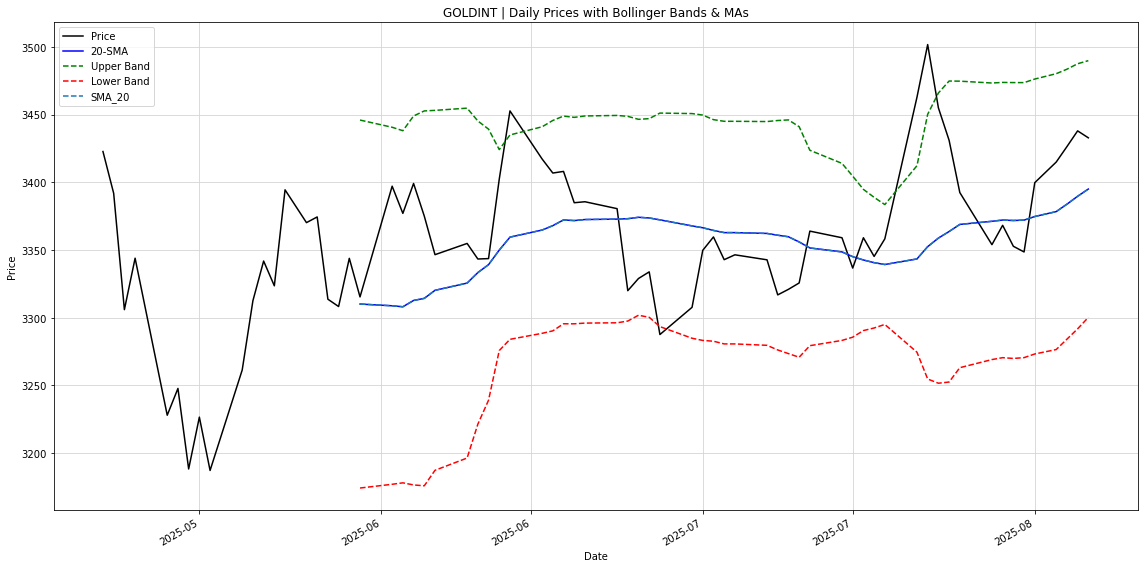

In [402]:
# === SETTINGS ===
instrument = "MIF"        # Options: MIF, MGF, KSE100, KMI30, GoldPK, GoldINT
interval = "Daily"        # Options: Daily, Weekly, Monthly, Quarterly, Yearly
timeframe = "Quarter"     # Options: Day, Week, Month, Quarter, Half-Year, Year, YTD, All

#process_instrument("MIF", interval, timeframe)
#process_instrument("KMI30", interval, timeframe)

#process_instrument("KMI30", interval, timeframe)
#process_instrument("GoldPK", interval, timeframe)

#process_instrument("GoldPK", interval, timeframe)
#process_instrument("GoldINT", interval, timeframe)

for inst in INSTRUMENT_PATHS.keys():
    print(f"\n📊 Processing: {inst}")
    process_instrument(inst, interval, timeframe)

#if instrument:  # if user specified one
#    process_instrument(instrument, interval, timeframe)
#else:  # run for all instruments
#    for inst in INSTRUMENT_PATHS.keys():
#        print(f"\n📊 Processing: {inst}")
#        process_instrument(inst, interval, timeframe)

In [27]:
# Extract 'data' part
data = jsonfile["data"]

# Convert to DataFrame
df = pd.DataFrame(data)

# Rename columns
df.rename(columns={"s_date": "datetime", "s_close": "price"}, inplace=True)

# Convert column types
df["datetime"] = pd.to_datetime(df["datetime"])
df["price"] = df["price"].astype(float)

# Save to Excel
output_path = excel_file
df.to_excel(output_path, index=False)

print(f"Data saved to {output_path}")

Data saved to D:/repos/PriceData/MGF.xlsx


In [ ]:
# === Plot ===
plt.figure(figsize=(16, 8))
plt.plot(df.index, df[price_column], label='Price', color='black')
plt.plot(df.index, df['SMA_20'], label='20-Day SMA', color='blue')
plt.plot(df.index, df['Upper_Band'], label='Upper Bollinger Band', color='green', linestyle='--')
plt.plot(df.index, df['Lower_Band'], label='Lower Bollinger Band', color='red', linestyle='--')

if df['MA_Weekly'].notna().any():
    plt.plot(df.index, df['MA_Weekly'], label='4-Week MA', color='orange')
if df['MA_Monthly'].notna().any():
    plt.plot(df.index, df['MA_Monthly'], label='6-Month MA', color='purple')
if df['MA_Yearly'].notna().any():
    plt.plot(df.index, df['MA_Yearly'], label='1-Year MA', color='brown')

plt.title(f'{instrument} - Price with Bollinger Bands and Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()

save_plot(instrument="MIF", interval=interval, timeframe=timeframe)
plt.show()